# Week 2

Week1에서 우리는 **텍스트 데이터를 인공지능이 이해할 수 있는 숫자 형태로 변환하는 준비 과정**을 마쳤습니다. 문장 속 단어들을 정제(cleaning)하고, 토큰화(tokenization)하여, 모델이 학습할 수 있도록 **정수 시퀀스(숫자 벡터)** 로 변환했죠.

Week2에서는, 그 데이터를 **실제로 인공지능 모델에 학습시키는 단계**로 넘어갑니다. 이번 주차에서는 “AI가 데이터를 학습하며 패턴을 익히는 과정”을 직접 경험해봅시다!

[4주 흐름](../README.md)과 [실행 환경 안내](../docs/runtime.md)를 먼저 확인해주세요.


### 이번 주차의 학습 목표


- Week1에서 만든 데이터를 바탕으로 **인공지능 모델을 실제로 학습(fit)** 시켜봅니다.
- 학습 과정에서 **손실(Loss)** 과 **정확도(Accuracy)** 가 어떻게 변화하는지 관찰합니다.
- **검증 데이터(validation)** 를 통해 일반화의 개념을 알아봅니다.
- **Epoch 수를 늘려가며 과적합(Overfitting)** 의 발생을 직접 실험해봅니다.



### 파일 구조

```text
gdg-7th-ai-mission/
├── week1/
│   ├── README.md
│   └── week1_mission.ipynb
├── week2/
│   ├── README.md
│   └── week2_mission.ipynb 
├── docs/runtime.md
├── artifacts/
│   └── week1/
│       └── week1_state.json
├── pyproject.toml
├── uv.lock
└── README.md
```


### ⚓️ Mission

이번 실습에서는 **준비 코드는 제공하고, 모델 학습에 필요한 핵심 동작을 직접 작성**합니다.

- **[제공 코드]** 는 그대로 실행해주세요.
- **[⚓️ 미션]** 에서는 TODO 안내에 따라 `...`를 코드로 바꿔주세요.
- 각 단계의 **실행 결과 확인**에서 출력과 그래프를 직접 확인해주세요.
- **⭐️ 개념 정리**와 **생각해보기**는 아래의 답변 셀에 작성해주세요.
- 코드를 수정했다면 해당 셀부터 아래로 다시 실행해주세요.

이 노트북에는 정답과 실행 출력이 없습니다. 미션을 채운 뒤 위에서부터 실행해주세요.


#### 1. Week1 데이터 불러오기


[실행 환경 안내](../docs/runtime.md)를 확인하고, Week1에서 저장한 `week1_state.json`을 준비해주세요. 아래 제공 코드는 저장한 데이터와 단어 사전을 불러오는 부분입니다. 그대로 실행해주세요.

Colab에서는 JSON을 업로드하거나 Drive를 연결하고, `STATE_PATH`를 파일 위치에 맞게 바꿔주세요.


In [ ]:
# 로컬에서는 주석으로 둡니다. 웹 Colab에서만 필요한 줄을 해제해주세요.
# from google.colab import files
# files.upload()  # pyproject.toml 선택
# import sys
# print(sys.version)  # Python 3.12 확인
# assert sys.version_info[:2] == (3, 12), "Python 3.12 런타임을 선택해주세요."
# %pip install uv
# !uv pip install --python {sys.executable} -r /content/pyproject.toml
# 설치 후 Python 커널을 재시작하고 import 셀부터 실행해주세요.

# Drive의 입력과 결과를 사용할 때만 실행합니다.
# from google.colab import drive
# drive.mount('/content/drive')


In [2]:
# [제공 코드] 라이브러리와 파일 위치를 준비합니다.
import json
import re
import sys
from pathlib import Path

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

ROOT_DIR = Path.cwd().resolve()
if ROOT_DIR.name == 'week2' and (ROOT_DIR.parent / 'pyproject.toml').is_file():
    ROOT_DIR = ROOT_DIR.parent
STATE_PATH = ROOT_DIR / 'artifacts' / 'week1' / 'week1_state.json'
SAVE_DIR = ROOT_DIR / 'artifacts' / 'week2'

# Colab에 JSON만 업로드했다면 입력 위치를 바꿔주세요.
# STATE_PATH = Path('/content/week1_state.json')
# Drive를 사용한다면 실제 보관 위치에 맞게 바꿔주세요.
# STATE_PATH = Path('/content/drive/MyDrive/gdg-mission/week1/week1_state.json')
# SAVE_DIR = Path('/content/drive/MyDrive/gdg-mission/week2')

SEED = 42
SAVE_DIR.mkdir(parents=True, exist_ok=True)
print('Python version:', sys.version)
print('TensorFlow version:', tf.__version__)
print('1주차 입력:', STATE_PATH)
print('2주차 결과:', SAVE_DIR)


Python version: 3.12.14 (main, Aug 12 2026, 13:57:54) [Clang 21.0.0 (clang-2100.1.1.101)]
TensorFlow version: 2.21.0
1주차 입력: /Users/leejiwoo/Desktop/gdg-7th-ai-mission/artifacts/week1/week1_state.json
2주차 결과: /Users/leejiwoo/Desktop/gdg-7th-ai-mission/artifacts/week2


In [3]:
# [제공 코드] 1주차와 같은 정제·라벨·인코딩 동작입니다.
def clean_str(string):
    string = re.sub(r'[^가-힣ㄱ-ㅎㅏ-ㅣA-Za-z0-9]', ' ', string)
    return ' '.join(string.lower().split())


def make_labels(rows):
    labels = [1 if int(row.split('\t', 1)[0]) >= 4 else 0 for row in rows]
    return np.array(labels, dtype=np.int64).reshape(-1, 1)


def encode_texts(texts, vectorize_layer):
    cleaned_texts = [clean_str(sentence) for sentence in texts]
    inputs = tf.constant(cleaned_texts, dtype=tf.string)
    return vectorize_layer(inputs)


if not STATE_PATH.is_file():
    raise FileNotFoundError('week1_state.json을 준비한 뒤 STATE_PATH를 확인해주세요.')
state = json.loads(STATE_PATH.read_text(encoding='utf-8'))
VOCAB_SIZE = int(state['vocab_size'])
MAX_LEN = int(state['max_len'])
vectorize_layer = tf.keras.layers.TextVectorization(
    standardize=None,
    split='whitespace',
    max_tokens=VOCAB_SIZE,
    output_mode='int',
    output_sequence_length=MAX_LEN,
    vocabulary=state['vocabulary'],
)

train_rows = state['train_rows']
validation_rows = state['validation_rows']
test_rows = state['test_rows']
train_text_X = [row.split('\t', 1)[1] for row in train_rows]
validation_text_X = [row.split('\t', 1)[1] for row in validation_rows]
test_text_X = [row.split('\t', 1)[1] for row in test_rows]

train_X = encode_texts(train_text_X, vectorize_layer)
validation_X = encode_texts(validation_text_X, vectorize_layer)
test_X = encode_texts(test_text_X, vectorize_layer)
train_Y = make_labels(train_rows)
validation_Y = make_labels(validation_rows)
test_Y = make_labels(test_rows)


In [4]:
# Week1에서 분리해둔 test_rows에서 리뷰 문장만 추출합니다.
test_text_X = [row.split('\t', 1)[1] for row in test_rows]

# Week1에서 학습된 vectorize_layer 그대로 사용합니다.
test_X = encode_texts(test_text_X, vectorize_layer)

print("test_X shape:", test_X.shape)
print("test_Y shape:", test_Y.shape)


test_X shape: (60000, 25)
test_Y shape: (60000, 1)


Week1에서 나눠둔 `test_rows`에서,  `split('\t', 1)[1]`을 이용해 두 번째 항목인 **리뷰 문장**만 추출합니다. (사용할 리뷰 수는 전처리 결과에 따라 달라질 수 있어요.) 저는 60000개가 나오네요! 

```text
test_X shape: (테스트 리뷰 수, 25)
test_Y shape: (테스트 리뷰 수, 1)
```

Week1에서 우리는 `train_text_X`로부터 **단어 사전**을 학습(`adapt`)하고, 해당 사전을 이용해`train_X`를 정수 시퀀스로 벡터화했죠.   

Week2는 **동일한 사전(vectorize_layer)** 을 이용해 **`test` 데이터**를 벡터화합니다. 이렇게 해야 훈련 데이터와 테스트 데이터에서 같은 단어가 같은 번호로 변환됩니다. 

예를 들어, 훈련 데이터에서 ‘배송’을 10으로 바꿨다면 테스트 데이터에서도 ‘배송’을 10으로 바꿔야 합니다. 모델은 훈련할 때 사용한 단어 번호를 기준으로 학습하기 때문에, 테스트 데이터를 변환할 때도 동일한 단어 사전 체계를 유지해야 해요. 



#### 2. 하이퍼파라미터 설정하기


이제 본격적으로 **감정 분석(Sentiment Analysis)** 을 수행하는 **모델을 만들어봅시다.** 앞서 데이터를 전처리하고, 텍스트를 숫자로 바꾸는 벡터화 과정을 마쳤습니다.

이번 단계에서는 학습 과정 전반을 제어하는 **하이퍼파라미터(Hyperparameters)** 를 설정할 거에요.

**⭐️ 개념 정리**

- 하이퍼파라미터(Hyperparameter)란 무엇일까요?
- `VOCAB_SIZE` , `EMBEDDING_DIM`,  `MAX_LEN` , `EPOCHS` , `BATCH_SIZE` 의 역할에 대해서 정리해주세요.


> (답변)  

하이퍼파라미터는 학습 모델의 구조나, 학습 방식을 결정하기 위해 설정하는 값이다.  
대표적인 하이퍼 파라미터에는 다음이 있다.  
- 학습률(Learning Rate)
- 배치 사이즈(Batch Size) : 가중치 업데이트 1회에 사용할 학습 데이터의 개수
- Epochs(학습 횟수) : 전체 학습 데이터를 몇번 반복하여 학습할지 결정하는 값
- Optimizer(최적화 알고리즘) : Cost Function의 값을 줄이는 방향으로 가중치를 업데이트 하는 방법
- Layer와 각 레이어의 뉴런수 등  

설정값과 역할들  
- `VOCAB_SIZE` : 모델이 사용할 단어 사전의 최대 크기
- `EMBEDDING_DIM` : 각 토큰을 표현하는 임베딩 벡터의 차원
- `MAX_LEN` : 모델에 입력할 토큰 시퀀스의 최대 길이  
- `EPOCHS` : 반복하여 학습할 횟수
- `BATCH_SIZE` : 가중치 업데이트 1회에 사용할 학습 데이터의 개수

In [5]:
# 모델의 주요 설정값들을 미리 정의해줍니다.
# VOCAB_SIZE와 MAX_LEN은 Week1에서 저장한 설정을 그대로 사용합니다.
EMBEDDING_DIM = 128
EPOCHS = 10
BATCH_SIZE = 32

#### 3. 신경망 구조 정의하기


신경망 구조(Neural Network Architecture)를 정의하는 부분입니다. 인공지능이 입력 데이터를 받아들이고, 내부에서 의미를 학습하며, 최종적으로 결과를 예측할 수 있도록 **신경망의 전체 흐름**(입력층 → 은닉층 → 출력층) 을 설계하는 단계입니다.

📺 [3Blue1Brown, 뉴럴네트워크라는걸 들어 보셨다면 보셔야 할 영상. - DL1](https://youtu.be/wrguEHxk_EI?si=_KA7dYmOi4vBEEad)

    위 링크는 손글씨 숫자 이미지를 입력으로 받아, 0~9 중 하나로 분류하는 다층 퍼셉트론(MLP) 구조를 설명하는 3Blue1Brown 한국어 영상입니다.  

    비록 우리는 이미지 데이터를 입력으로 사용하지는 않지만, 영상 속 이미지 분류와 이번 텍스트 분류는 데이터를 숫자 벡터로 표현해 신경망에 넣고, 정해진 라벨 중 하나로 분류한다는 점에서 비슷해요. 한 번쯤 시청하는 걸 추천드립니다.




**⭐️ 개념 정리**

모델을 만들기 전에, 각 레이어가 어떤 역할을 하는지 정리해보아요.

- Embedding이란 무엇인지 정리해주세요.
- Pooling이란 무엇인지 정리해주세요.
- Dense Layer의 역할에 대해서 설명해주세요.
- 활성화함수인 ReLU와 sigmoid의 역할을 정리해주세요.


> (답변)  

**Embedding(임베딩)**
- 단어(토큰)의 의미적 특징을 학습할 수 있도록 실수 벡터로 변환하는 과정
- 텍스트 전처리 과정에서 정제된 각 토큰은 정수 인덱스로 변환되었음
- 변환된 정수 인덱스를 신경망이 학습할 수 있는 벡터 표현으로 변환하는 것이다
- 이를 통해 의미나 문맥이 유사한 토큰들이 벡터 공간에서 유사한 표현을 갖도록 학습시킬 수 있음

**Pooling**
- 여러 특징값을 기준에 따라 하나의 대표값으로 요약하여 크기(차원)을 줄이는 과정
- 대표적으로 Max Pooling(말그대로 최댓값 선택), Average Pooling(말그대로 평균값 계산해서 선택)
- 여러 토큰의 임베딩을 하나의 벡터로 줄일 수 있음

**Dense Layer**
- Dense? 밀집한? -> '완전연결'을 의미한다
- 이전 Layer의 모든 출력이 다음 Layer의 각 뉴런과 연결
- 입력값에 가중치를 곱한 해서 합한것 + 편항(bias) 연산을 수행
- 학습과정에서 가중치(weight)와 편향(bias)가 조정됨
- 활성화함수를 통해서 비선형적인 관계도 학습(더 복잡한 관계를 학습할 수 있다)

**ReLU와 sigmoid**
- ReLU
    - 음수면 -> 0으로, 0과 양수는 -> 그대로 출력한다
    - `max(0, x)` 로 구현한다
- Sigmoid
    - 입력값을 0과 1 사이의 값으로 변환한다.
    - y = 1 / (1 + e^(-x)) 로 함수이다.(치역은 0과 1 사이)
    - 0~1 사이의 값이므로, 마치 출력값을 그 특정 클래스에 속할 확률로 생각할 수 있다

**[⚓️ 미션] Keras를 사용해 신경망을 직접 구현해보아요.**


`tf.keras.Sequential`은 리스트에 넣은 레이어들을 순서대로 연결합니다.

(Sequential과 관련된 기본 문법은 케라스 공식 문서를 참고해보세요. [Sequential 가이드](https://keras.io/guides/sequential_model/))

아래 코드의 주석을 참고해 `Sequential` 안에 코드를 작성해주세요. 입력층은 제공되어 있으니, 각 주석에 알맞는 레이어 코드를 작성해주세요!




In [6]:
tf.keras.utils.set_random_seed(SEED)

model = tf.keras.Sequential([
    
    tf.keras.Input(shape=(MAX_LEN,), dtype='int64'),  # 입력층

    # 은닉층 - Embedding 레이어 (사전 크기: VOCAB_SIZE, 벡터 차원: EMBEDDING_DIM)
    tf.keras.layers.Embedding(
        input_dim = VOCAB_SIZE,
        output_dim = EMBEDDING_DIM
    ),

    # 은닉층 - Pooling 레이어 (힌트: GlobalAveragePooling1D() 또는 GlobalMaxPooling1D())
    tf.keras.layers.GlobalAveragePooling1D(),

    # 은닉층 - Dense 레이어 (뉴런 64개, 활성화함수: 'relu')
    tf.keras.layers.Dense(64, activation = 'relu'),

    # 출력층 — Dense 레이어 (뉴런 1개, 활성화함수: 'sigmoid')
    tf.keras.layers.Dense(1, activation = 'sigmoid')

])

model.summary()
initial_weights = [weight.copy() for weight in model.get_weights()]

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 25, 128)        │       256,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 264,321 (1.01 MB)

 Trainable params: 264,321 (1.01 MB)

 Non-trainable params: 0 (0.00 B)

이제 정리한 내용을 바탕으로 모델을 만들어봅시다! 

우리 모델은 리뷰 문장 하나, 즉 정수 토큰 25개를 입력받습니다. Embedding 레이어는 각 토큰을 128차원 벡터로 바꿉니다.

이렇게 만들어진 25개의 벡터는 Pooling을 거치면서 문장을 나타내는 128차원 벡터 하나로 압축됩니다.

이후 Dense 레이어가 문장 벡터를 64개의 특징으로 변환하고, ReLU를 적용해 복잡한 패턴을 학습할 수 있도록 합니다.

마지막 Dense 레이어는 값 하나를 만들고, sigmoid가 이를 0~1 사이의 긍정 점수로 바꿉니다. 이 점수가 0.5보다 크면 긍정, 그렇지 않으면 부정으로 분류합니다.

리뷰 하나를 기준으로 전체 구조를 정리하면 다음과 같아요.

```text
정수 토큰 25개
   (25,)
     ↓ Embedding
   (25, 128)
     ↓ Pooling 
   (128,)
     ↓ Dense(64) + ReLU
   (64,)
     ↓ Dense(1) + sigmoid
   (1,) → 긍정 점수 하나
```





#### 4. 학습 방법 설정하기


In [7]:
model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])


모델이 학습할 때 어떤 방식으로 학습할지(최적화 알고리즘), 무엇을 기준으로 성능을 평가할지(손실 함수, 평가 지표) 정의하는 부분입니다.

**⭐️ 개념 정리**

- Optimizer(최적화 함수)에 대해서 정리해주세요.
- Loss Function(손실 함수)에 대해서 정리해주세요.
- Metrics(평가지표)에 대해서 정리해주세요.

참고 자료

- [딥러닝의 학습 방법 — WikiDocs](https://wikidocs.net/36033)


> (답변)

**Optimizer(최적화 함수)**
- Cost Function(비용)을 줄이는 방향으로 가중치(weight)와 편향(bias) 같은 파라미터를 업데이트하는 알고리즘
- 모델의 예측값과 실제값을 비교하여 계산한 손실을 줄이는 방향으로 조정
- Gradient Descent(경사하강법)을 기반으로 하는 Adam이 있다  
- adam은 기울기의 1/2차 모멘트 추정치를 활용하여 파라미터별 업데이트 크기를 점진적으로 조절
    - 1차 모멘트(지수 이동 평균 - 기울기가 최근에 어느방향으로 대체로 변하는지)
    - 2차 모멘트(기울기 제곱의 지수이동 평균 - 제곱이므로 무조건 양수, 클수록 제곱은 더 큼)

**Loss Function(손실 함수)**
- 모델의 예측값과 실제값의 차이를 수치화 하는 함수
- 쉽게 말하면, 모델이 얼마나 틀렸는지를 계산( 덜 틀리는 방향으로 파라미터를 조절해야 할 것임)

**Metrics(평가지표)**
- 모델의 예측 성능을 확인하기 위해 사용하는 평가 기준
- 학습 과정에서 얼마나 좋은 예측을 하는지 확인하는데에 사용
- 이번 미션에서 사용하는 `accuracy`는 (정답을 맞힌 데이터 수)/(전체 데이터 수) 이다!


#### 5. 모델 학습과 학습 곡선 확인하기


In [8]:
history = model.fit(
    train_X, train_Y,
    epochs = EPOCHS,  # TODO: 학습 횟수
    batch_size = BATCH_SIZE,  # TODO: 배치 크기
    validation_data = (validation_X, validation_Y),
    verbose = 1
)


Epoch 1/10
3500/3500 ━━━━━━━━━━━━━━━━━━━━ 2s 638us/step - accuracy: 0.8207 - loss: 0.3839 - val_accuracy: 0.8499 - val_loss: 0.3406
Epoch 2/10
3500/3500 ━━━━━━━━━━━━━━━━━━━━ 2s 630us/step - accuracy: 0.8465 - loss: 0.3396 - val_accuracy: 0.8504 - val_loss: 0.3364
Epoch 3/10
3500/3500 ━━━━━━━━━━━━━━━━━━━━ 2s 613us/step - accuracy: 0.8492 - loss: 0.3309 - val_accuracy: 0.8504 - val_loss: 0.3358
Epoch 4/10
3500/3500 ━━━━━━━━━━━━━━━━━━━━ 2s 619us/step - accuracy: 0.8512 - loss: 0.3250 - val_accuracy: 0.8499 - val_loss: 0.3377
Epoch 5/10
3500/3500 ━━━━━━━━━━━━━━━━━━━━ 2s 621us/step - accuracy: 0.8525 - loss: 0.3210 - val_accuracy: 0.8489 - val_loss: 0.3395
Epoch 6/10
3500/3500 ━━━━━━━━━━━━━━━━━━━━ 2s 622us/step - accuracy: 0.8536 - loss: 0.3178 - val_accuracy: 0.8483 - val_loss: 0.3414
Epoch 7/10
3500/3500 ━━━━━━━━━━━━━━━━━━━━ 2s 619us/step - accuracy: 0.8549 - loss: 0.3150 - val_accuracy: 0.8482 - val_loss: 0.3426
Epoch 8/10
3500/3500 ━━━━━━━━━━━━━━━━━━━━ 2s 620us/step - accuracy: 0.8560 -

**[⚓️ 미션]** `epochs`와 `batch_size`의 빈칸을 채워, train data를 이용해 모델을 학습시켜봅시다.

**HINT:** 앞에서 설정한 `EPOCHS`와 `BATCH_SIZE`를 사용해주세요.

훈련 데이터를 10 epoch 동안 반복 학습하고, Week1에서 따로 나눠둔 검증 데이터를 `validation_data`로 전달합니다. 

이처럼 test data 외에, 검증 데이터를 따로 분리하는 이유는 무엇일까요? 검증 데이터의 용도는 모델의 과적합을 확인하기 위함입니다. 

훈련 손실과 검증 손실 곡선을 그려 과적합을 확인해 볼까요?

아래 그래프 코드는 그대로 실행해주세요.


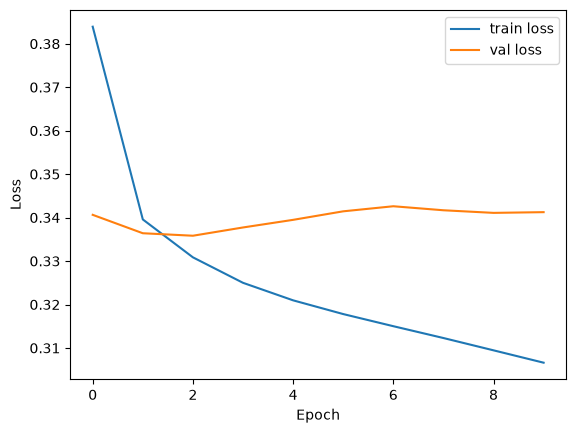

In [9]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()


검증 데이터는 모델 학습, 즉 모델의 가중치 업데이트에 사용하지 않아요. 매 epoch이 끝날 때마다 훈련 손실(`loss`)과 함께 검증 손실(`val_loss`)을 계산하는 데 사용됩니다.

모델은 훈련 데이터의 손실을 줄이는 방향으로 학습하기에, epoch을 반복할수록 훈련 손실(`loss`)은 계속해서 줄어드는 형태를 띕니다. 반면 학습에 사용하지 않은 검증 데이터의 손실(`val_loss`)은 처음에는 줄어들다가, 어느 순간부터 다시 증가하는 모습을 보입니다.

이렇게 훈련 손실은 계속 줄어드는데 검증 손실은 오히려 커지는 현상이 **과적합(Overfitting)** 입니다. 

- **검증 손실이 줄어드는 구간**: 모델이 데이터 전반에 공통된 패턴을 배워가고 있는 구간
- **검증 손실이 다시 증가하는 구간**: 모델이 훈련 데이터에만 지나치게 맞춰지기 시작하는 구간

따라서 검증 손실이 가장 낮은 지점을 살펴보는 것이 중요합니다. 이번 실습에서는 마지막 epoch까지 학습한 모델을 평가하고, 8단계에서 학습 횟수에 따른 변화를 비교해볼 거예요.


#### 6. 테스트 데이터로 평가하기


In [10]:
test_loss, test_acc = model.evaluate(test_X, test_Y, verbose=0)
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")


Test Loss: 0.3359, Test Accuracy: 0.8507


훈련에 사용되지 않은 test data를 이용해 모델의 일반화 성능을 평가합니다.

`evaluate()` 함수는

- 손실값(`test_loss`): 모델이 예측을 얼마나 잘못했는지
- 정확도(`test_acc`): 올바르게 맞춘 비율
을 계산해줍니다.


#### 7. 새로운 리뷰 예측하기


In [12]:
# [미션] 리뷰를 두 개 이상 작성하고 긍정/부정 분류 조건을 채워주세요.
example_sentences = [
    # TODO: 직접 작성한 리뷰 두 개 이상을 넣어주세요.
    "여기 초밥 먹으면 다른 초밥 못먹을거 같아요!!!! 회 크기도 좋고 특히 장어초밥 장어가 커서 좋아요 맛있어요",
    "배달은 빨리 왔는데 차갑고 닭이 질겨요.. 너무 실망스러워서 다시는 안먹을 것 같아요ㅠ",
    "진짜 잘~ 하는 짓거리이십니다 , 이런식으로 장사하시면... 말을 아끼겠습니다",
    "오늘 한번 먹고 말거같아요..",
    "오늘 한 번 먹고 말거같아요..ㅠ",
    "사과는 빨갛다",
    "쓸 만 해요",
    "쓸만해요",
]

example_seq = encode_texts(example_sentences, vectorize_layer)
pred = model.predict(example_seq, verbose=0)

for s, p in zip(example_sentences, pred):

    # TODO: p[0] > 0.5이면 긍정, 그렇지 않으면 부정
    label = "긍정 👍" if p[0] > 0.5 else "부정 👎" 

    print(f"문장: {s}")
    print(f"긍정 점수: {p[0]:.4f}")
    print("결과:", label)


문장: 여기 초밥 먹으면 다른 초밥 못먹을거 같아요!!!! 회 크기도 좋고 특히 장어초밥 장어가 커서 좋아요 맛있어요
긍정 점수: 0.9998
결과: 긍정 👍
문장: 배달은 빨리 왔는데 차갑고 닭이 질겨요.. 너무 실망스러워서 다시는 안먹을 것 같아요ㅠ
긍정 점수: 0.0152
결과: 부정 👎
문장: 진짜 잘~ 하는 짓거리이십니다 , 이런식으로 장사하시면... 말을 아끼겠습니다
긍정 점수: 0.4321
결과: 부정 👎
문장: 오늘 한번 먹고 말거같아요..
긍정 점수: 0.6432
결과: 긍정 👍
문장: 오늘 한 번 먹고 말거같아요..ㅠ
긍정 점수: 0.3119
결과: 부정 👎
문장: 사과는 빨갛다
긍정 점수: 0.3617
결과: 부정 👎
문장: 쓸 만 해요
긍정 점수: 0.5434
결과: 긍정 👍
문장: 쓸만해요
긍정 점수: 0.2548
결과: 부정 👎


**[⚓️ 미션]** `example_sentences`에 원하는 리뷰를 두 개 이상 쓴 뒤, 점수에 따라 `label`을 정하는 코드를 작성해주세요. 참고로 이모지와 문장부호는 전처리에서 제거되며, 정제 후 공백으로 나눈 토큰이 25개를 넘으면 뒤쪽 내용이 잘리니 유의해주세요!

**HINT:** `label = "긍정 😊" if 조건 else "부정 😞"` 형태로 작성할 수 있어요.

학습된 모델이 실제 문장을 입력받아 감정을 예측하는 과정입니다. `vectorize_layer`를 통해 문장을 숫자 시퀀스로 변환한 뒤, `model.predict()`를 이용해 각 문장의 **긍정 점수**를 계산합니다. 출력값이 0.5보다 크면 긍정으로, 그렇지 않으면 부정으로 분류해요. 이 점수가 실제 확률과 항상 정확하게 일치하는 것은 아니에요. 이를 통해 모델이 새로운 문장에서도 학습된 감정 패턴을 얼마나 잘 적용하는지를 확인할 수 있습니다.

**생각해보기:**

- 직접 쓴 문장의 예측이 예상과 같았나요? 예상과 다르거나 판단이 애매한 문장을 하나 골라, 예측 결과와 점수를 정리해주세요.


> (답변)

리뷰를 뭘 쓸까 하다가, 리뷰이벤트했던 내 배민리뷰를 하나 가져왔다.(첫번째 초밥리뷰)
부정적인 내용의 리뷰도 실험해보고 싶어서, 배민을 돌아다니면서 평점이 낮은 몇 리뷰를 가져왔다.  
첫번째, 두번째 처럼 직설적으로 이야기한건 긍정점수를 봐도 양 극단에 있을정도로 확신을 가지는 것 같다.  
너무 잘하길래,, 문장을 좀 비꼬는 식으로 바꿔서 해봤다.

"진짜 잘~ 하는 짓거리이십니다 , 이런식으로 장사하시면... 말을 아끼겠습니다"
- 이 정도면 나름 비꼬는 말투로 만들었는데, 그런데도 예측을 '부정'으로 해낸 모습이다.
- (진짜 리뷰가 아니고 만든 문장입니다.)
- 그래도 앞선 (확실한) 부정리뷰보다는 확실히 긍정점수가 올라간 모습
- 좀 더 애매하게 해보자..

"오늘 한번 먹고 말거같아요.."
- 드디어 이 모델을 속이는데에 성공했다.
- 한번 먹고 만다는건 재주문하지 않겠다는거고 이건 부정리뷰에 가까울 것인데,
- 너무 짧아서 판단에 쓸 토큰이 많지 않았는지 '긍정'으로 예측한 모습이다.

"오늘 한 번 먹고 말거같아요..ㅠ"
- 앞선 리뷰와 똑같은 문장에 눈물을 의미하는 'ㅠ'를 붙여줬다.
- 정제 과정에서 단일 자음이나 모음은 그대로 남기기 때문에, 이 'ㅠ'때문에 다르게 판정할까 궁금했는데,,
- 정말로 잘 예측했다! 신기하다...

"사과는 빨갛다"
- 긍정도, 부정도 아닌 문장은 어떻게 예측할까 궁금해서 해봤다.
- 이도 저도 아니니 긍정점수가 0.5 근처일거라 기대했는데,  
- 꽤 낮은 긍정점수로 '부정'을 예측한 모습이다. 

#### 8. Epoch 수를 늘려 과적합 비교하기

**Epoch 수를 늘렸을 때 과적합(Overfitting)이 발생하는지** 직접 확인해보아요. 기존에는 **`EPOCHS = 10`** 으로 설정하여 학습을 진행했는데요, 이번엔 **`Epoch = 30`으로 늘려** 학습을 오래 지속했을 때 손실과 정확도가 어떻게 달라지는지를 비교해보아요. 

**훈련 손실(train loss)** 과 **검증 손실(val loss)**, 그리고 **훈련 정확도(train accuracy)** 와 **검증 정확도(val accuracy)** 의 변화를 비교하여 시각화하고, 매 epoch의 `loss`와 `val_loss` 값을 숫자로 출력해 직접 확인해주세요.

이번 단계는 제공 코드를 그대로 실행해주세요! 기존 모델에 30회를 더 학습하는 대신, **같은 초기 가중치의 새 모델**을 처음부터 30회 학습합니다.


Epoch 1/30
3500/3500 ━━━━━━━━━━━━━━━━━━━━ 2s 632us/step - accuracy: 0.8207 - loss: 0.3839 - val_accuracy: 0.8499 - val_loss: 0.3406
Epoch 2/30
3500/3500 ━━━━━━━━━━━━━━━━━━━━ 2s 648us/step - accuracy: 0.8465 - loss: 0.3396 - val_accuracy: 0.8504 - val_loss: 0.3364
Epoch 3/30
3500/3500 ━━━━━━━━━━━━━━━━━━━━ 2s 620us/step - accuracy: 0.8492 - loss: 0.3309 - val_accuracy: 0.8504 - val_loss: 0.3358
Epoch 4/30
3500/3500 ━━━━━━━━━━━━━━━━━━━━ 2s 621us/step - accuracy: 0.8512 - loss: 0.3250 - val_accuracy: 0.8499 - val_loss: 0.3377
Epoch 5/30
3500/3500 ━━━━━━━━━━━━━━━━━━━━ 2s 628us/step - accuracy: 0.8525 - loss: 0.3210 - val_accuracy: 0.8489 - val_loss: 0.3395
Epoch 6/30
3500/3500 ━━━━━━━━━━━━━━━━━━━━ 2s 626us/step - accuracy: 0.8536 - loss: 0.3178 - val_accuracy: 0.8483 - val_loss: 0.3414
Epoch 7/30
3500/3500 ━━━━━━━━━━━━━━━━━━━━ 2s 640us/step - accuracy: 0.8549 - loss: 0.3150 - val_accuracy: 0.8482 - val_loss: 0.3426
Epoch 8/30
3500/3500 ━━━━━━━━━━━━━━━━━━━━ 5s 1ms/step - accuracy: 0.8560 - l

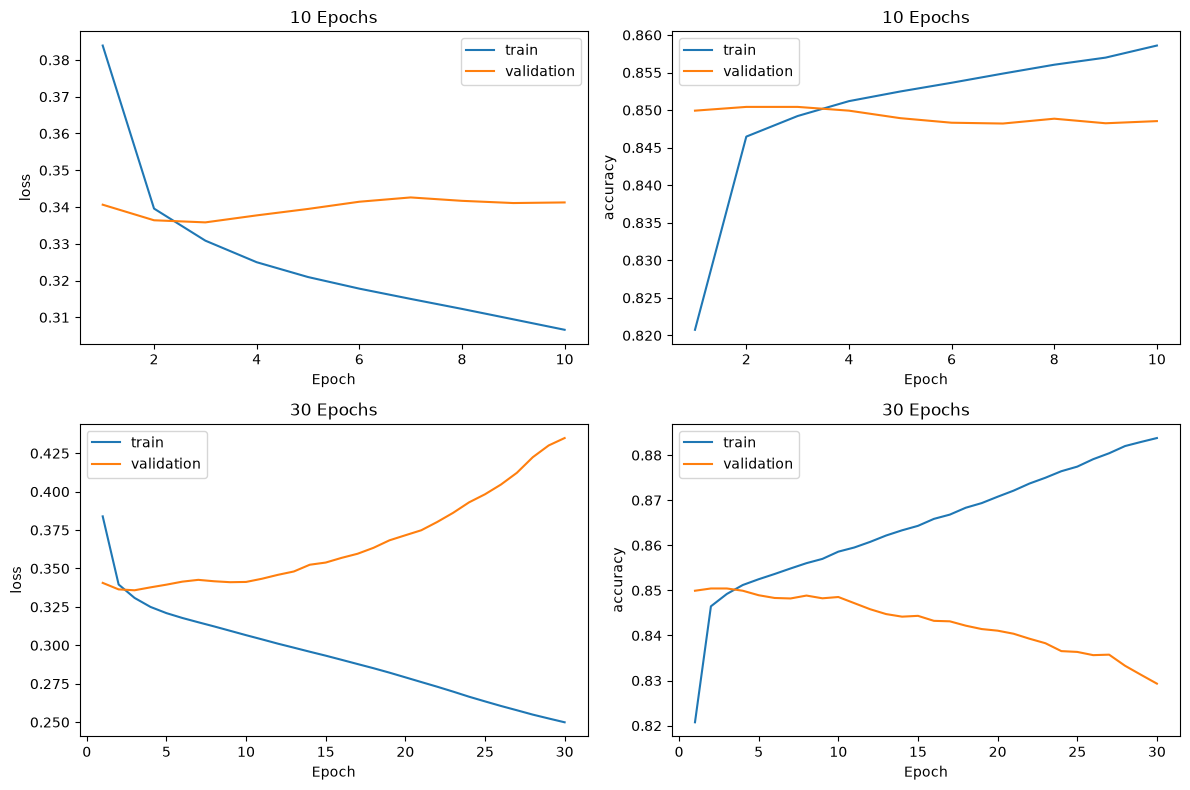

Epoch 1: loss=0.3839, val_loss=0.3406
Epoch 2: loss=0.3396, val_loss=0.3364
Epoch 3: loss=0.3309, val_loss=0.3358
Epoch 4: loss=0.3250, val_loss=0.3377
Epoch 5: loss=0.3210, val_loss=0.3395
Epoch 6: loss=0.3178, val_loss=0.3414
Epoch 7: loss=0.3150, val_loss=0.3426
Epoch 8: loss=0.3123, val_loss=0.3417
Epoch 9: loss=0.3095, val_loss=0.3411
Epoch 10: loss=0.3066, val_loss=0.3412
Epoch 11: loss=0.3039, val_loss=0.3433
Epoch 12: loss=0.3011, val_loss=0.3459
Epoch 13: loss=0.2985, val_loss=0.3481
Epoch 14: loss=0.2958, val_loss=0.3524
Epoch 15: loss=0.2933, val_loss=0.3539
Epoch 16: loss=0.2906, val_loss=0.3569
Epoch 17: loss=0.2878, val_loss=0.3596
Epoch 18: loss=0.2851, val_loss=0.3635
Epoch 19: loss=0.2822, val_loss=0.3683
Epoch 20: loss=0.2792, val_loss=0.3716
Epoch 21: loss=0.2761, val_loss=0.3749
Epoch 22: loss=0.2731, val_loss=0.3803
Epoch 23: loss=0.2699, val_loss=0.3862
Epoch 24: loss=0.2666, val_loss=0.3930
Epoch 25: loss=0.2635, val_loss=0.3983
Epoch 26: loss=0.2605, val_loss=0.

In [29]:
# [제공 코드] 같은 초기 가중치의 새 모델을 총 30회 학습합니다.
tf.keras.utils.set_random_seed(SEED)
model_30 = tf.keras.models.clone_model(model)
model_30.set_weights(initial_weights)
model_30.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
history_30 = model_30.fit(
    train_X, train_Y,
    epochs=30,
    batch_size=BATCH_SIZE,
    validation_data=(validation_X, validation_Y),
    verbose=1,
)

# 10회·30회 실험의 손실과 정확도를 비교합니다.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, (result, title) in enumerate([(history, '10 Epochs'), (history_30, '30 Epochs')]):
    epochs = range(1, len(result.history['loss']) + 1)
    for col, metric in enumerate(['loss', 'accuracy']):
        axes[row, col].plot(epochs, result.history[metric], label='train')
        axes[row, col].plot(epochs, result.history['val_' + metric], label='validation')
        axes[row, col].set_title(title)
        axes[row, col].set_xlabel('Epoch')
        axes[row, col].set_ylabel(metric)
        axes[row, col].legend()
plt.tight_layout()
plt.show()

for epoch, (loss, val_loss) in enumerate(
    zip(history_30.history['loss'], history_30.history['val_loss']), start=1
):
    print(f'Epoch {epoch}: loss={loss:.4f}, val_loss={val_loss:.4f}')

best_epoch = int(np.argmin(history_30.history['val_loss'])) + 1
print('검증 손실이 가장 낮은 Epoch:', best_epoch)


**생각해보기:**

- 출력된 `loss`와 `val_loss` 값과 그래프를 바탕으로, **과적합(Overfitting)의 징후가 나타났는지** 정리해주세요. 나타났다면 어느 구간인지 함께 적어주세요.
- `EPOCHS`를 늘리면 무조건 성능이 좋아질까요? 실험 결과를 바탕으로 설명해주세요.

과적합이 뚜렷하게 나타나지 않았다면, 실제로 관찰한 결과를 그대로 정리해주세요.


> (답변)

**과적합의 징후**
- 약 3 Epoch 이후 과적합의 징후가 나타났다.  
- Train에 대한 Loss는 지속적으로 감소하는데, Validation에 대한 Loss는 살짝 반등하는 모습이었다.  
- 특히 30 Epoch 까지 학습한 그래프에서, Train Loss는 약 0.250까지도 감소했는데,  
- 동시에 Validation Accuracy도 약 83%까지 하락했다.  
- 이는 학습이 진행될수록 어느 순간부터 검증 데이터에 대한 정확도는 오히려 떨어진다는 것이다
- 학습이 진행될수록 모델이 train data에만 지나치게 맞춰지는 과적합 현상이 있음을 확인한 것이다

**Epochs를 늘린다고 해서..**
- 학습 횟수를 계속 늘린다고 해서 성능이 무조건 쭉쭉 좋아지는 것이 아니다
- 어느 순간부터는, train 데이터에만 맞춰져서, train에 대한 accuracy는 높은데도 정작 validation에 대한 정확도는 떨어진다
- 따라서, 실제 모델을 개선할때에는 EarlyStopping 등의 방식으로 이런 문제가 발생하지 않도록 해야할 것이다!


### 마무리

- `TODO`의 핵심 코드를 작성하고 위에서 아래로 실행해주세요.
- 출력과 그래프를 확인하고, 실행 결과가 의미하는 바를 정리해주세요.
- **개념 정리**와 **생각해보기**는 노트북의 답변 셀에 원하는 분량만큼 작성해주세요.
- WIL에는 알게 된 점, 막힌 지점, 해결 방법을 300자 이상 작성해주세요.

이번 주차는 코드 작성보다 개념 정리에 비중을 두었습니다. 직접 작성할 코드의 양은 많지 않지만, 각 코드가 어떤 역할을 하고 어떤 개념을 담고 있는지 이해하는 것이 더 중요하기 때문이에요. 빈칸을 채우는 데서 끝내지 않고, 코드의 의미를 자신의 언어로 정리해보는 시간을 가지면 좋을 것 같아요.


### 📺 3주차를 위한 추천 영상

3주차에는 트랜스포머 기반 모델인 BERT를 배웁니다. 트랜스포머는 한 주 안에 이해하기 어려울 수 있어요. 미리 공부해보고 싶으신 분들은 아래 영상을 시청해주세요!

[트랜스포머 이해를 위한 추천 영상](https://youtu.be/g38aoGttLhI?si=OJwT07kdcH7hfaZ0)
